# Import Module

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mempersiapkan Data

In [ ]:
# Daca data csv
df = pd.read_csv('/content/drive/MyDrive/Data Fluks/data_juni_ST2_7D_clean.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.head()

,timestamp,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s)
0,2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00
1,2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00
2,2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28
3,2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00
4,2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00


In [ ]:
# Mengubah "Timestamp" menjadi indeks
df = df.set_index("timestamp")
df = df.sort_index()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 14 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     float64
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
dtypes: float64(13), int64(1)
memory usage: 222.6 MB


# Menghitung Parameter Meteorologi

- Parameter Mass Density of Air
  
  $ \rho_a = \frac{p}{R \times T} \quad [\mathrm{kg\ m^{-3}}] $


In [ ]:
R = 8.314472 # Konstanta gas universal (J/mol/K)
Md = 0.02897  # Massa Molekul Udara Kering (kg/mol)
Ra = R/Md # Konstanta udara (J/kg/K)
df['Temperature (K)'] = df["Temperature (Celsius)"] + 273.15 # Suhu (Kelvin)
df['Air Pressure (Pa)'] = df["Air Pressure (kPa)"] * 1000 # Tekanan udara (Pa)
df['Mass Density of Air (kg/m^3)'] = df['Air Pressure (Pa)']/(Ra* df['Temperature (K)']) # Densitas udara (mol/m³)

- Parameter Molar Density of Air

  $ \rho = \frac{p}{R \times T} \quad [\mathrm{ mol\ m^{-3}}] $

In [ ]:
df['Molar Density of Air (mol/m^3)'] = df['Air Pressure (Pa)']/(R* df['Temperature (K)']) # Densitas udara (mol/m³)

- Parameter Molar Volume of Air
  
  $ v_a = \frac{R \times T}{p} \quad [\mathrm{m^{3}\ mol^{-1}}] $

In [ ]:
df["Molar Volume of Air (m^3/mol)"] = (R*df["Temperature (K)"])/df["Air Pressure (Pa)"]

- Parameter Saturation Vapor Pressure $e_s$ (kPa)

  $e_s(T) = 0.611 \cdot \exp\left( \frac{17.502 \cdot T}{T + 240.97} \right) \quad [\text{kPa}]$

In [ ]:
df['Saturation Vapor Pressure (kPa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97))
df['Saturation Vapor Pressure (Pa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97)) * 1000

- Parameter Water Vapor Partial Pressure $e$ (kPa)

  $e \;=\; \mathrm{RH}\cdot e_s(T) \quad [\text{kPa}]$

In [ ]:
df['Water Vapor Partial Pressure (kPa)'] = 0.01 * df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)']
df['Water Vapor Partial Pressure (Pa)'] = 0.01 * df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)'] * 1000

- Parameter Dew point temperature $T_{dew}$ (K)
  
  $T_{\text{dew}} = 240.97 \cdot \frac{\ln\left(\frac{e}{0.611}\right)}{17.502 - \ln\left(\frac{e}{0.611}\right)} + 273.16 \quad [\text{K}]$

In [ ]:
df['Dew point temperature  (K)'] = 240.97 * (np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611) / (17.502 - np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611))) + 273.16

- Parameter H2O Mole Fraction $\chi_{\mathrm{H_2O}}$
  
  $\chi_{\mathrm{H_2O}} = \frac{e}{p} \quad [\mathrm{mmol\ mol_a^{-1}}]$
  


In [ ]:
df['H2O Mole Fraction (mmol/mol_a)'] = (df['Water Vapor Partial Pressure (kPa)'] * 1000)/df['Air Pressure (kPa)']

- Parameter H2O Mixing Ratio $r_{H_2O}$
  
  $r_{H_2O} = \frac{e}{p - e} \quad [\mathrm{mmol\ mol_d^{-1}}]$

In [ ]:
df['H2O Mixing Ratio (mmol/mol_d)'] = (df['Water Vapor Partial Pressure (kPa)'] * 1000)/(df['Air Pressure (kPa)'] - df['Water Vapor Partial Pressure (kPa)'])

- Parameter CO2 Mixing Ratio $r_{\mathrm{CO_2}}$
  
 $r_{\mathrm{CO_2}} = \frac{x_{\mathrm{CO_2}}}{1 - x_{\mathrm{H_2O}}} \quad [\mathrm{\mu mol\ mol_d^{-1}}]$

In [ ]:
df['CO2 Mixing Ratio (µmol/mol_d)'] = 10e6 * (df['C02 mole fraction (µmol/mol_a)'])/(10e6 - (df['H2O Mole Fraction (mmol/mol_a)'] * 1000))

- Parameter Angin

  $ w = atas - bawah$

In [ ]:
# Membuat parameter 'w'
df['w (m/s)'] = df['atas (m/s)'] - df['bawah (m/s)']

- Parameter $w'$ (angin sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $w' = w - \bar{w}$

In [ ]:
# Menghitung rata-rata angin tiap interval 30 menit
df['w_mean_30min'] = df['w (m/s)'].resample('30min').transform('mean')

# Menghitung fluktuasi dengan reynold decomposistion
df['w_prime'] = df['w (m/s)'] - df['w_mean_30min']

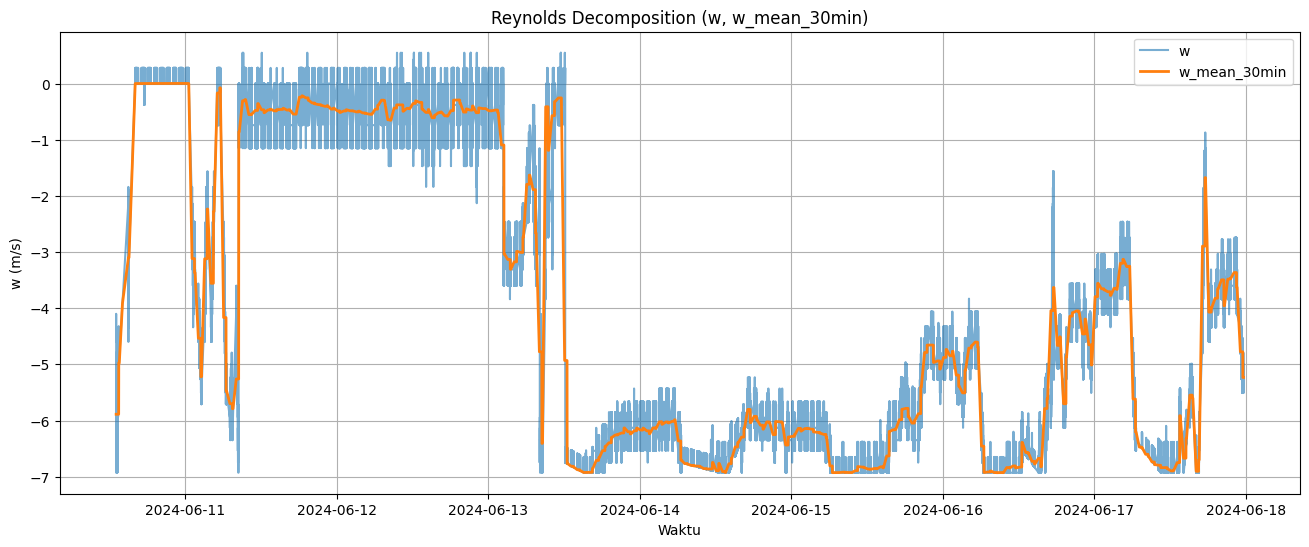

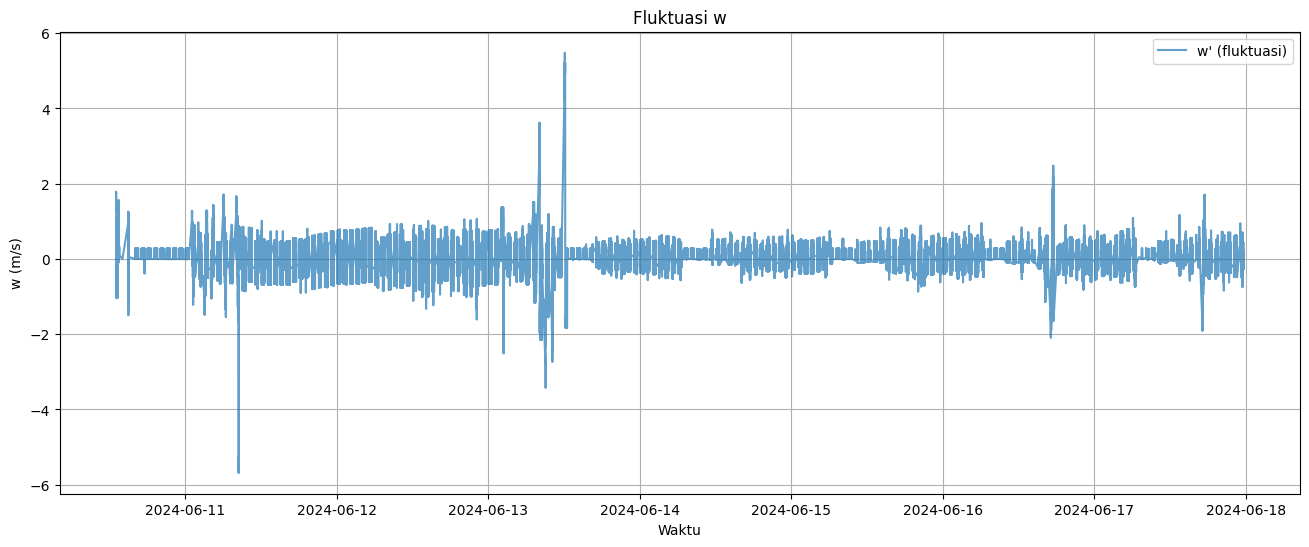

In [ ]:
# Plot 1
plt.figure(figsize=(16,6))
plt.plot(df.index, df["w (m/s)"], label="w", alpha=0.6)
plt.plot(df.index, df["w_mean_30min"], label="w_mean_30min", linewidth=2)

plt.legend()
plt.title("Reynolds Decomposition (w, w_mean_30min)")
plt.xlabel("Waktu")
plt.ylabel("w (m/s)")
plt.grid(True)
plt.show()

# plot 2
plt.figure(figsize=(16,6))
plt.plot(df.index, df["w_prime"], label="w' (fluktuasi)", alpha=0.7)

plt.legend()
plt.title("Fluktuasi w")
plt.xlabel("Waktu")
plt.ylabel("w (m/s)")
plt.grid(True)
plt.show()

- Parameter $c'$ ($CO_2$ sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $c' = c - \bar{c}$

In [ ]:
# Menghitung CO2 rata-rata tiap interval 30 menit
df['c_mean_30min'] = df['C02 mole fraction (µmol/mol_a)'].resample('30min').transform('mean')

# Menghitung fluktuasi dengan reynold decomposistion
df['c_prime'] = df['C02 mole fraction (µmol/mol_a)'] - df['c_mean_30min']

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


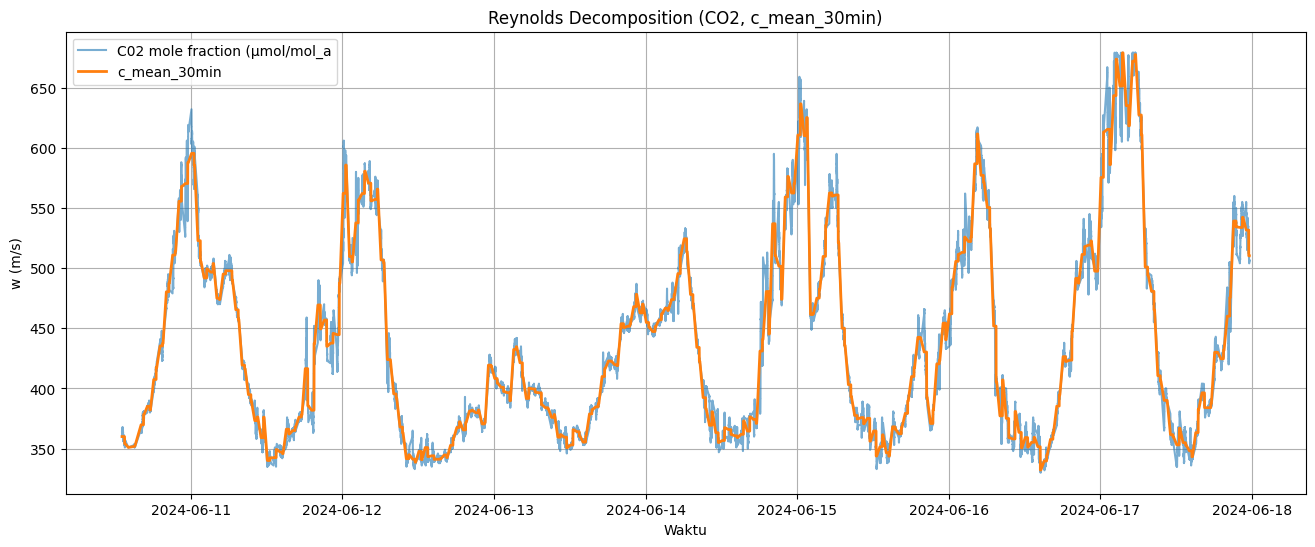

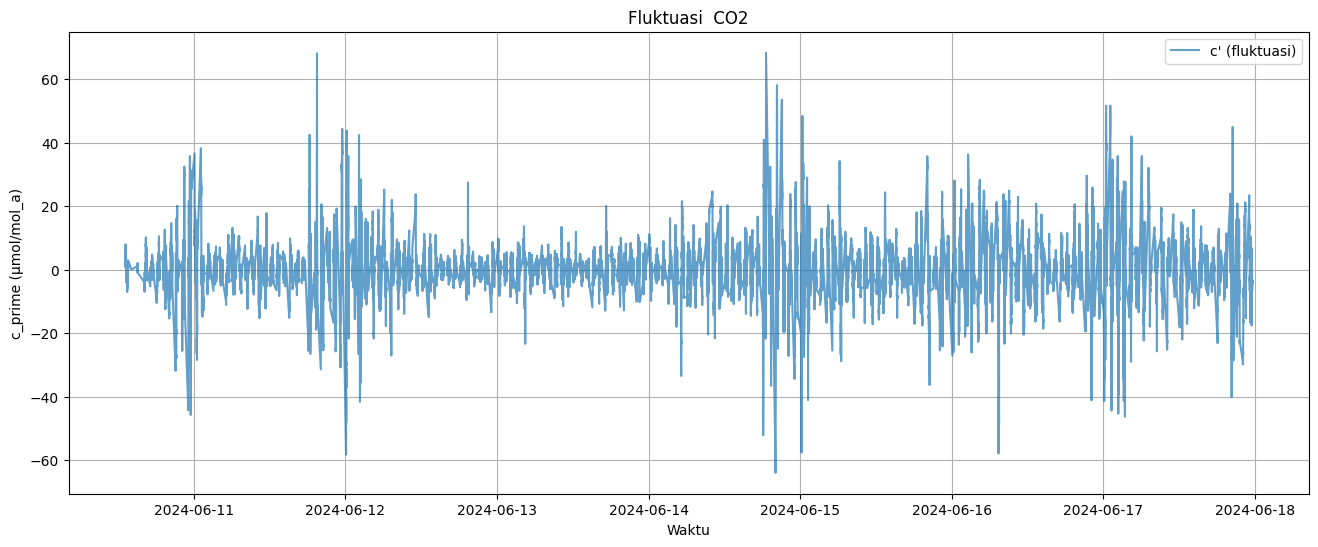

In [ ]:
# Plot 1
plt.figure(figsize=(16,6))
plt.plot(df.index, df["C02 mole fraction (µmol/mol_a)"], label="C02 mole fraction (µmol/mol_a", alpha=0.6)
plt.plot(df.index, df["c_mean_30min"], label="c_mean_30min", linewidth=2)

plt.legend()
plt.title("Reynolds Decomposition (CO2, c_mean_30min)")
plt.xlabel("Waktu")
plt.ylabel("w (m/s)")
plt.grid(True)
plt.show()

# plot 2
plt.figure(figsize=(16,6))
plt.plot(df.index, df["c_prime"], label="c' (fluktuasi)", alpha=0.7)

plt.legend()
plt.title("Fluktuasi  CO2")
plt.xlabel("Waktu")
plt.ylabel("c_prime (µmol/mol_a)")
plt.grid(True)
plt.show()

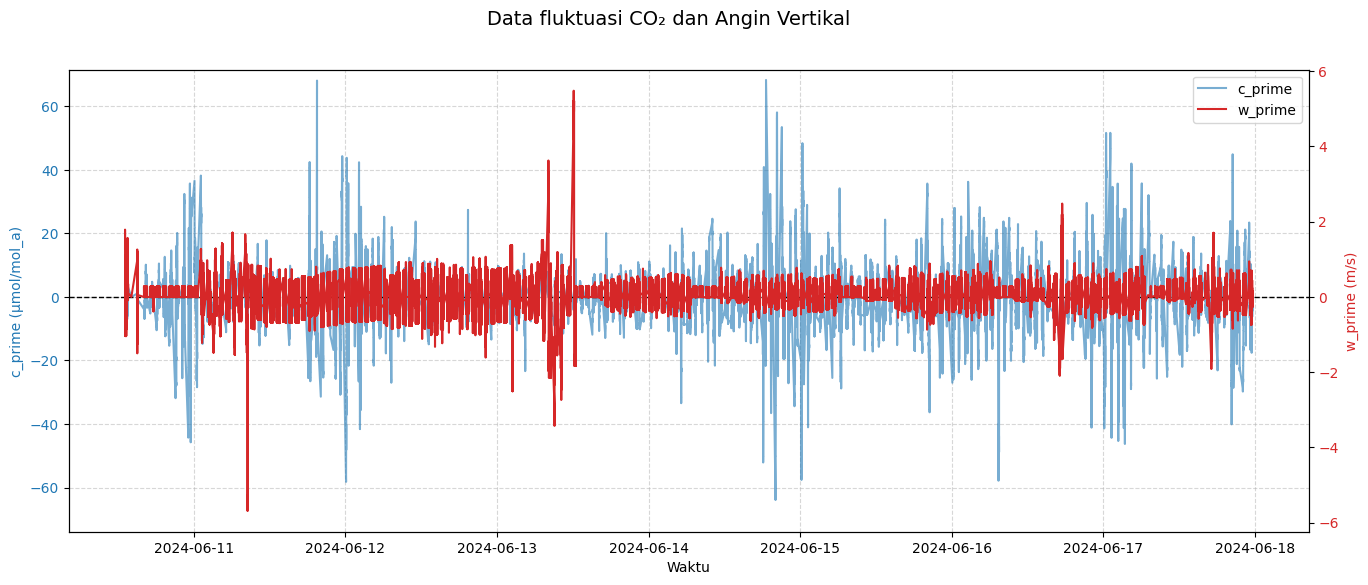

In [ ]:
# Fungsi bantu: samakan posisi nol
def align_yaxis_zero(ax1, ax2):
    y1_min, y1_max = ax1.get_ylim()
    y2_min, y2_max = ax2.get_ylim()

    # proporsi posisi nol di masing-masing axis
    y1_range = y1_max - y1_min
    y2_range = y2_max - y2_min

    y1_zero = -y1_min / y1_range
    y2_zero = -y2_min / y2_range

    # cari pergeseran
    shift = y1_zero - y2_zero

    if shift > 0:
        # geser axis2
        new_min = y2_min - shift * y2_range
        new_max = y2_max - shift * y2_range
        ax2.set_ylim(new_min, new_max)
    else:
        # geser axis1
        new_min = y1_min + shift * y1_range
        new_max = y1_max + shift * y1_range
        ax1.set_ylim(new_min, new_max)


# Plot dengan double y-axis
fig, ax1 = plt.subplots(figsize=(16,6))

ax1.plot(df.index, df["c_prime"], label="c_prime", color="tab:blue", alpha=0.6)
ax1.set_xlabel("Waktu")
ax1.set_ylabel("c_prime (µmol/mol_a)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(df.index, df["w_prime"], label="w_prime", color="tab:red", linewidth=1.5)
ax2.set_ylabel("w_prime (m/s)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

fig.suptitle("Data fluktuasi CO₂ dan Angin Vertikal", fontsize=14)
ax1.grid(True, linestyle="--", alpha=0.5)

# Samakan posisi nol
align_yaxis_zero(ax1, ax2)

# Tambah garis nol biar lebih jelas
ax1.axhline(0, color="black", linewidth=1, linestyle="--")

# Legend gabungan
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.show()


In [ ]:
df.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,Water Vapor Partial Pressure (Pa),Dew point temperature (K),H2O Mole Fraction (mmol/mol_a),H2O Mixing Ratio (mmol/mol_d),CO2 Mixing Ratio (µmol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,...,2692.594272,295.471102,26.704470,27.437165,364.974645,-4.60,-5.888737,1.288737,360.036798,3.963202
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,...,2698.628118,295.507897,26.752161,27.487511,363.973708,-4.86,-5.888737,1.028737,360.036798,2.963202
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,...,2697.301814,295.499815,26.738760,27.473364,363.973219,-4.32,-5.888737,1.568737,360.036798,2.963202
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,...,2693.168794,295.474609,26.698171,27.430515,363.971738,-4.86,-5.888737,1.028737,360.036798,2.963202
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,...,2702.080674,295.528919,26.786484,27.523749,363.974961,-4.86,-5.888737,1.028737,360.036798,2.963202
2024-06-10 13:06:02.091,100.874000,27.758665,37.597103,74.485390,27.232393,363.0,0,1942.560187,2.79,0.00,...,2690.885415,295.460668,26.675708,27.406804,363.970918,-4.60,-5.888737,1.288737,360.036798,2.963202
2024-06-10 13:06:02.254,100.876038,27.762419,37.553703,74.436562,27.275118,363.0,0,1945.878187,2.79,0.87,...,2695.864984,295.491056,26.724533,27.458344,363.972700,-4.86,-5.888737,1.028737,360.036798,2.963202
2024-06-10 13:06:02.422,100.874970,27.761484,37.522923,74.384674,27.259096,363.0,0,1942.800096,2.79,0.87,...,2691.456983,295.464159,26.681118,27.412515,363.971116,-4.86,-5.888737,1.028737,360.036798,2.963202
2024-06-10 13:06:02.583,100.874741,27.759705,37.512325,74.485390,27.275118,363.0,0,1947.154624,2.79,0.87,...,2697.633390,295.501836,26.742407,27.477214,363.973352,-4.60,-5.888737,1.288737,360.036798,2.963202


- Parameter Kovarians antara $w'$ dengan $c'$

  $\overline{w'c'} = cov(w', c') = \frac{1}{N} \sum_{i=1}^{n} w'c'$

In [ ]:
# Menghitung perkalian w_prime dan c_prime
df['w/CO2_cov'] = df['w_prime'] * df['c_prime']

# Resample per 30 menit dan hitung rata-rata
df_mean = df.resample('30min').mean(numeric_only=True).interpolate(method='time')

In [ ]:
# Hitung jumlah data per 30 menit
counts = df.resample("30T").size()

ideal_count = 7 * 1800  # 7 Hz * 1800 detik (30 menit)

# Gabungkan ke dataframe
df_30min = df_mean.copy()
df_30min["actual_count"] = counts
df_30min["missing_data"] = ideal_count - counts
df_30min["accuracy_percent"] = (counts / ideal_count * 100).round(2)

# Atur urutan kolom: pindahkan 3 kolom ini ke depan
cols = ["actual_count", "missing_data", "accuracy_percent"] + [c for c in df_30min.columns if c not in ["actual_count", "missing_data", "accuracy_percent"]]
df_30min = df_30min[cols]

/tmp/ipython-input-819333001.py:2: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  counts = df.resample("30T").size()


In [ ]:
df_30min.head(20)

,actual_count,missing_data,accuracy_percent,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),...,Dew point temperature (K),H2O Mole Fraction (mmol/mol_a),H2O Mixing Ratio (mmol/mol_d),CO2 Mixing Ratio (µmol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,8832,3768,70.10,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,...,296.423658,28.300732,29.125569,361.058579,-5.888737,-5.888737,-4.444915e-17,360.036798,1.647635e-15,-1.298012
2024-06-10 13:30:00,2218,10382,17.60,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,...,297.430246,30.078594,31.011668,355.161609,-4.973237,-4.973237,4.825316e-16,354.093327,-2.649959e-14,-0.015544
2024-06-10 14:00:00,1,12599,0.01,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,...,298.497538,32.045554,33.106469,352.128415,-3.915409,-3.915409,0.000000e+00,351.000000,0.000000e+00,0.000000
2024-06-10 14:30:00,0,12600,0.00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,...,298.297514,31.664882,32.700510,352.587519,-3.507953,-3.507953,4.814241e-17,351.471069,6.578204e-15,0.020894
2024-06-10 15:00:00,1469,11131,11.66,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,...,298.097490,31.284210,32.294550,353.046623,-3.100497,-3.100497,9.628483e-17,351.942138,1.315641e-14,0.041789
2024-06-10 15:30:00,0,12600,0.00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,...,297.537031,30.248008,31.192694,361.990529,-1.549551,-1.549551,4.821600e-17,360.896496,7.983690e-15,0.020491
2024-06-10 16:00:00,8837,3763,70.13,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,...,296.976572,29.211806,30.090838,370.934434,0.001394,0.001394,1.471777e-19,369.850854,2.810974e-15,-0.000806
2024-06-10 16:30:00,2217,10383,17.60,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,...,297.098827,29.428944,30.321278,379.546377,0.000253,0.000253,2.914680e-20,378.429409,3.179334e-15,-0.000108
2024-06-10 17:00:00,8836,3764,70.13,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,...,297.128018,29.462538,30.356939,386.362413,0.002884,0.002884,-1.342369e-19,385.224083,8.929229e-15,-0.000424


# Menghitung Fluks

- Parameter Fluks $CO_2$

  $F_c = \rho \ \overline{w'c'} \quad [\mathrm{\mu mol\ m^{-2}\ s^{-1} }]$

In [ ]:
# Hitung flux Fc per 30 menit
df_30min['C02_flux (μmol/m²/s)'] = df_30min['w/CO2_cov'] * df_30min['Molar Density of Air (mol/m^3)']

In [ ]:
df_30min.isna().sum()

,0
actual_count,0
missing_data,0
accuracy_percent,0
Air Pressure (kPa),0
Air Temperature (Celcius),0
Altitude (MSAL),0
Relatif Humidity (%),0
Temperature (Celsius),0
C02 mole fraction (µmol/mol_a),0
CH4 mole fraction (µmol/mol_a),0


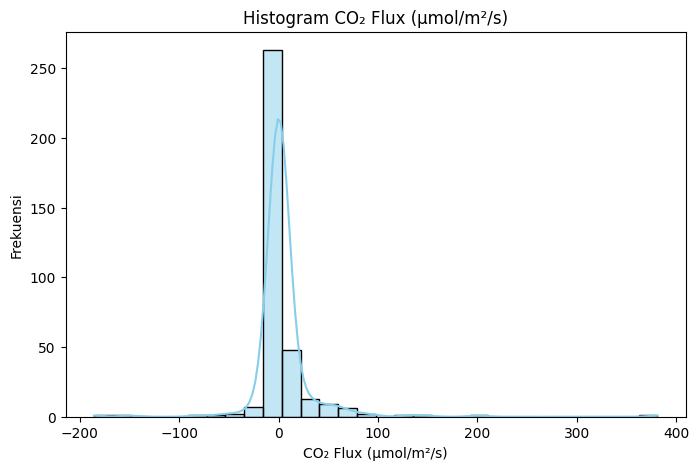

In [ ]:
# Menampilkan distribusi data
plt.figure(figsize=(8,5))
sns.histplot(df_30min['C02_flux (μmol/m²/s)'], bins=30, kde=True, color='skyblue')

plt.title('Histogram CO₂ Flux (μmol/m²/s)')
plt.xlabel('CO₂ Flux (μmol/m²/s)')
plt.ylabel('Frekuensi')
plt.show()

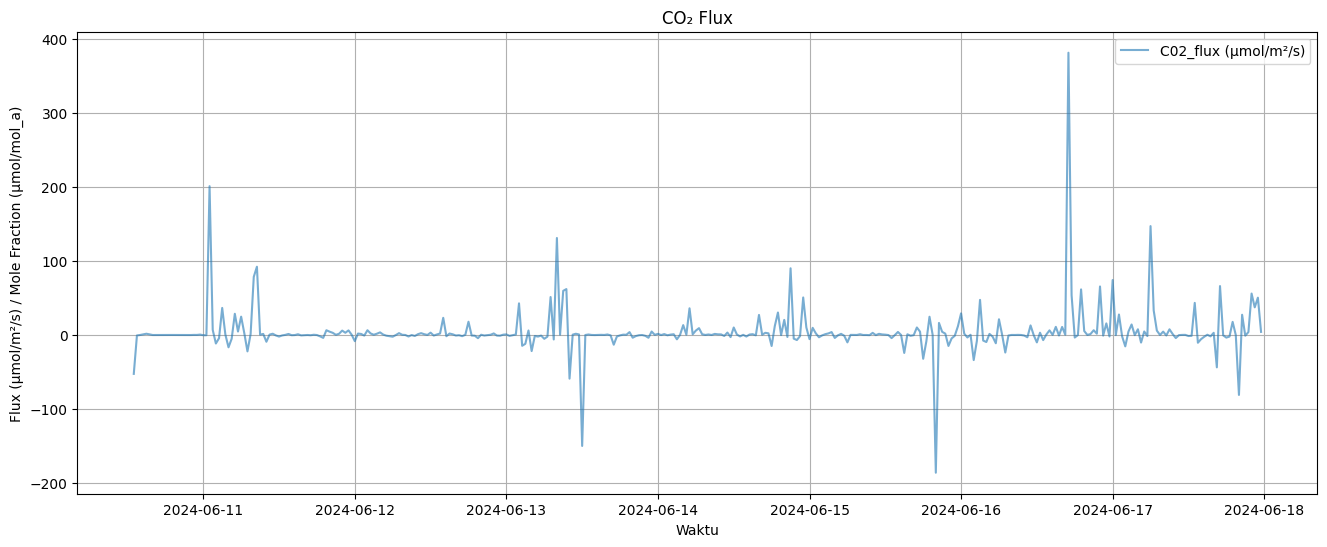

In [ ]:
# Plot 1
plt.figure(figsize=(16,6))
plt.plot(df_30min.index, df_30min['C02_flux (μmol/m²/s)'], label="C02_flux (μmol/m²/s)", alpha=0.6)

plt.legend()
plt.title("CO₂ Flux")
plt.xlabel("Waktu")
plt.ylabel("Flux (μmol/m²/s) / Mole Fraction (µmol/mol_a)")
plt.grid(True)
plt.show()

In [ ]:
# Isi data NaN dengan Interpolasi Time
final_flux = df_30min

final_flux.head(20)

,actual_count,missing_data,accuracy_percent,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),...,H2O Mole Fraction (mmol/mol_a),H2O Mixing Ratio (mmol/mol_d),CO2 Mixing Ratio (µmol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,8832,3768,70.10,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,...,28.300732,29.125569,361.058579,-5.888737,-5.888737,-4.444915e-17,360.036798,1.647635e-15,-1.298012,-52.502474
2024-06-10 13:30:00,2218,10382,17.60,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,...,30.078594,31.011668,355.161609,-4.973237,-4.973237,4.825316e-16,354.093327,-2.649959e-14,-0.015544,-0.627457
2024-06-10 14:00:00,1,12599,0.01,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,...,32.045554,33.106469,352.128415,-3.915409,-3.915409,0.000000e+00,351.000000,0.000000e+00,0.000000,0.000000
2024-06-10 14:30:00,0,12600,0.00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,...,31.664882,32.700510,352.587519,-3.507953,-3.507953,4.814241e-17,351.471069,6.578204e-15,0.020894,0.842378
2024-06-10 15:00:00,1469,11131,11.66,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,...,31.284210,32.294550,353.046623,-3.100497,-3.100497,9.628483e-17,351.942138,1.315641e-14,0.041789,1.691405
2024-06-10 15:30:00,0,12600,0.00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,...,30.248008,31.192694,361.990529,-1.549551,-1.549551,4.821600e-17,360.896496,7.983690e-15,0.020491,0.830854
2024-06-10 16:00:00,8837,3763,70.13,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,...,29.211806,30.090838,370.934434,0.001394,0.001394,1.471777e-19,369.850854,2.810974e-15,-0.000806,-0.032738
2024-06-10 16:30:00,2217,10383,17.60,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,...,29.428944,30.321278,379.546377,0.000253,0.000253,2.914680e-20,378.429409,3.179334e-15,-0.000108,-0.004406
2024-06-10 17:00:00,8836,3764,70.13,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,...,29.462538,30.356939,386.362413,0.002884,0.002884,-1.342369e-19,385.224083,8.929229e-15,-0.000424,-0.017266


- Parameter Fluks $CO_2$ Processing

  $F_c = \rho \ \overline{w'c'} \quad [\mathrm{\mu mol\ m^{-2}\ s^{-1} }]$
  
  Metode Processing:
  - Penghapusan Outlier
  - Imputasi Data

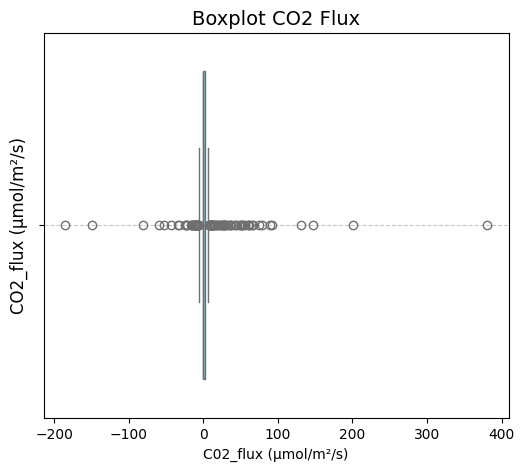

In [ ]:
# Menampilkan Boxplot
plt.figure(figsize=(6,5))
sns.boxplot(x=final_flux['C02_flux (μmol/m²/s)'], color="skyblue")

plt.title("Boxplot CO2 Flux", fontsize=14)
plt.ylabel("CO2_flux (μmol/m²/s)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [ ]:
Q1 = final_flux['C02_flux (μmol/m²/s)'].quantile(0.25)
Q3 = final_flux['C02_flux (μmol/m²/s)'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Ganti outlier dengan NaN
final_flux['C02_flux_processing (μmol/m²/s)'] = final_flux['C02_flux (μmol/m²/s)'].where((final_flux['C02_flux (μmol/m²/s)'] >= lower_bound) & (final_flux['C02_flux (μmol/m²/s)'] <= upper_bound), np.nan)


# Interpolasi berbasis waktu
final_flux['C02_flux_processing (μmol/m²/s)'] = final_flux['C02_flux_processing (μmol/m²/s)'].interpolate(method='time')

In [ ]:
final_flux.head(20)

,actual_count,missing_data,accuracy_percent,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),...,H2O Mixing Ratio (mmol/mol_d),CO2 Mixing Ratio (µmol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),C02_flux_processing (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,8832,3768,70.10,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,...,29.125569,361.058579,-5.888737,-5.888737,-4.444915e-17,360.036798,1.647635e-15,-1.298012,-52.502474,NaN
2024-06-10 13:30:00,2218,10382,17.60,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,...,31.011668,355.161609,-4.973237,-4.973237,4.825316e-16,354.093327,-2.649959e-14,-0.015544,-0.627457,-0.627457
2024-06-10 14:00:00,1,12599,0.01,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,...,33.106469,352.128415,-3.915409,-3.915409,0.000000e+00,351.000000,0.000000e+00,0.000000,0.000000,0.000000
2024-06-10 14:30:00,0,12600,0.00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,...,32.700510,352.587519,-3.507953,-3.507953,4.814241e-17,351.471069,6.578204e-15,0.020894,0.842378,0.842378
2024-06-10 15:00:00,1469,11131,11.66,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,...,32.294550,353.046623,-3.100497,-3.100497,9.628483e-17,351.942138,1.315641e-14,0.041789,1.691405,1.691405
2024-06-10 15:30:00,0,12600,0.00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,...,31.192694,361.990529,-1.549551,-1.549551,4.821600e-17,360.896496,7.983690e-15,0.020491,0.830854,0.830854
2024-06-10 16:00:00,8837,3763,70.13,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,...,30.090838,370.934434,0.001394,0.001394,1.471777e-19,369.850854,2.810974e-15,-0.000806,-0.032738,-0.032738
2024-06-10 16:30:00,2217,10383,17.60,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,...,30.321278,379.546377,0.000253,0.000253,2.914680e-20,378.429409,3.179334e-15,-0.000108,-0.004406,-0.004406
2024-06-10 17:00:00,8836,3764,70.13,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,...,30.356939,386.362413,0.002884,0.002884,-1.342369e-19,385.224083,8.929229e-15,-0.000424,-0.017266,-0.017266


In [ ]:
final_flux.isna().sum()

,0
actual_count,0
missing_data,0
accuracy_percent,0
Air Pressure (kPa),0
Air Temperature (Celcius),0
Altitude (MSAL),0
Relatif Humidity (%),0
Temperature (Celsius),0
C02 mole fraction (µmol/mol_a),0
CH4 mole fraction (µmol/mol_a),0


- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ s^{-1} }]$

In [ ]:
# Konversi satuan agar menjadi ton/Ha/s
final_flux['ton_hectare_flux'] = final_flux['C02_flux_processing (μmol/m²/s)'] * 44.001 * 1e-8

- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ week^{-1} }]$

In [ ]:
# Konversi satuan agar menjadi ton/Ha/week
sec_to_week = 604800
ton_flux_week = final_flux['ton_hectare_flux'] * sec_to_week
final_flux['ton_flux_week'] = ton_flux_week

- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ month^{-1} }]$

In [ ]:
# Konversi satuan agar menjadi ton/Ha/month
sec_to_month = 2629800
ton_flux_month = final_flux['ton_hectare_flux'] * sec_to_month
final_flux['ton_flux_month'] = ton_flux_month

- Parameter Fluks $CO_2$ dalam satuan $[\mathrm{ton\ ha^{-1}\ year^{-1} }]$

In [ ]:
# Konversi satuan agar menjadi ton/Ha/year
sec_to_year = 31557600
ton_flux_year = final_flux['ton_hectare_flux'] * sec_to_year
final_flux['ton_flux_year'] = ton_flux_year


final_flux.head(20)

,actual_count,missing_data,accuracy_percent,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),...,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),C02_flux_processing (μmol/m²/s),ton_hectare_flux,ton_flux_week,ton_flux_month,ton_flux_year
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,8832,3768,70.10,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,...,-4.444915e-17,360.036798,1.647635e-15,-1.298012,-52.502474,NaN,NaN,NaN,NaN,NaN
2024-06-10 13:30:00,2218,10382,17.60,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,...,4.825316e-16,354.093327,-2.649959e-14,-0.015544,-0.627457,-0.627457,-2.760875e-07,-0.166978,-0.726055,-8.712660
2024-06-10 14:00:00,1,12599,0.01,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,...,0.000000e+00,351.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
2024-06-10 14:30:00,0,12600,0.00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,...,4.814241e-17,351.471069,6.578204e-15,0.020894,0.842378,0.842378,3.706549e-07,0.224172,0.974748,11.696980
2024-06-10 15:00:00,1469,11131,11.66,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,...,9.628483e-17,351.942138,1.315641e-14,0.041789,1.691405,1.691405,7.442352e-07,0.450113,1.957190,23.486276
2024-06-10 15:30:00,0,12600,0.00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,...,4.821600e-17,360.896496,7.983690e-15,0.020491,0.830854,0.830854,3.655841e-07,0.221105,0.961413,11.536956
2024-06-10 16:00:00,8837,3763,70.13,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,...,1.471777e-19,369.850854,2.810974e-15,-0.000806,-0.032738,-0.032738,-1.440484e-08,-0.008712,-0.037882,-0.454582
2024-06-10 16:30:00,2217,10383,17.60,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,...,2.914680e-20,378.429409,3.179334e-15,-0.000108,-0.004406,-0.004406,-1.938739e-09,-0.001173,-0.005098,-0.061182
2024-06-10 17:00:00,8836,3764,70.13,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,...,-1.342369e-19,385.224083,8.929229e-15,-0.000424,-0.017266,-0.017266,-7.597233e-09,-0.004595,-0.019979,-0.239750


In [ ]:
final_flux.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 358 entries, 2024-06-10 13:00:00 to 2024-06-17 23:30:00
Freq: 30min
Data columns (total 42 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   actual_count                        358 non-null    int64  
 1   missing_data                        358 non-null    int64  
 2   accuracy_percent                    358 non-null    float64
 3   Air Pressure (kPa)                  358 non-null    float64
 4   Air Temperature (Celcius)           358 non-null    float64
 5   Altitude (MSAL)                     358 non-null    float64
 6   Relatif Humidity (%)                358 non-null    float64
 7   Temperature (Celsius)               358 non-null    float64
 8   C02 mole fraction (µmol/mol_a)      358 non-null    float64
 9   CH4 mole fraction (µmol/mol_a)      358 non-null    float64
 10  Water Vapor Mass Density (kg/m^3)   358 non-null    float64
 

# Visualisasi Data

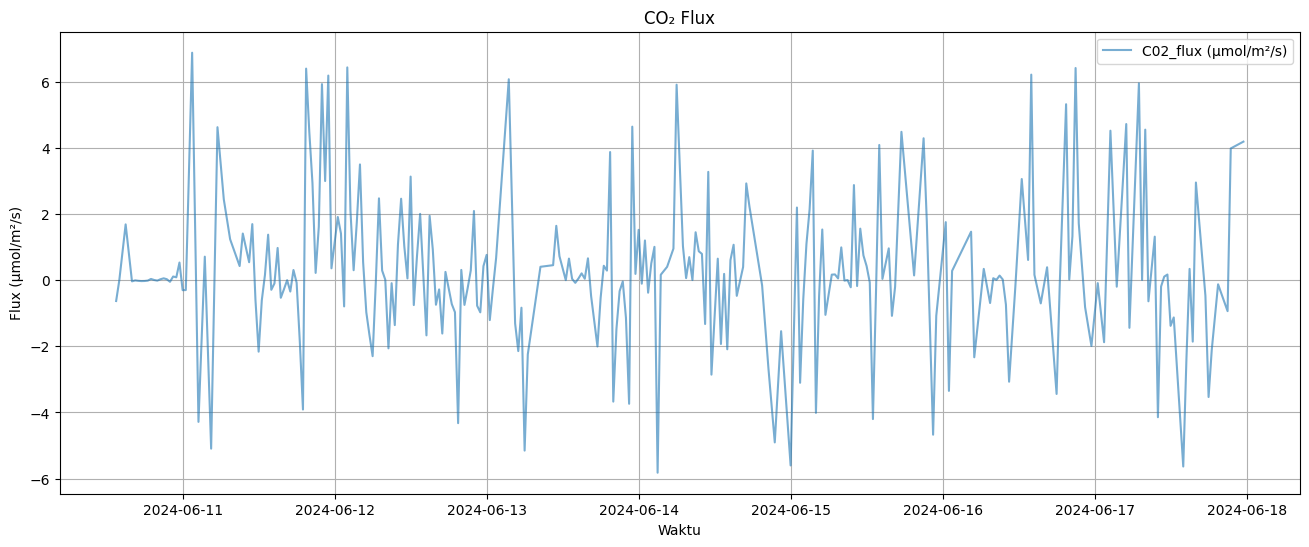

In [ ]:
# Plot 1
plt.figure(figsize=(16,6))
plt.plot(final_flux.index, final_flux['C02_flux_processing (μmol/m²/s)'], label="C02_flux (μmol/m²/s)", alpha=0.6)

plt.legend()
plt.title("CO₂ Flux")
plt.xlabel("Waktu")
plt.ylabel("Flux (μmol/m²/s)")
plt.grid(True)
plt.show()

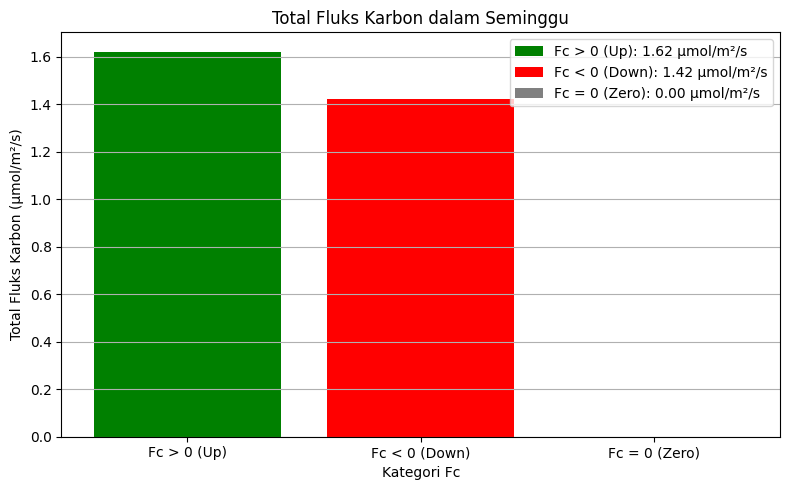

In [ ]:
# Ambil kolom Fc
Fc = final_flux['C02_flux_processing (μmol/m²/s)']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].mean()
Fc_neg_sum = -Fc[Fc < 0].mean()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

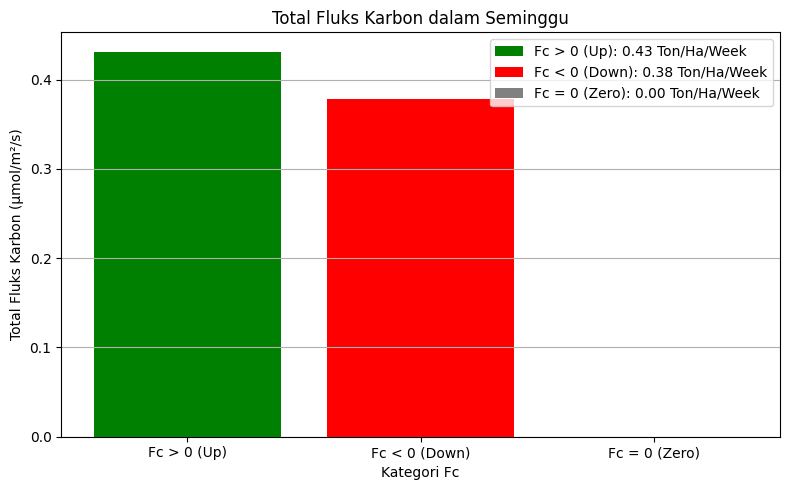

In [ ]:
# Ambil kolom Fc
Fc = final_flux['ton_flux_week']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].mean()
Fc_neg_sum = -Fc[Fc < 0].mean()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} Ton/Ha/Week")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

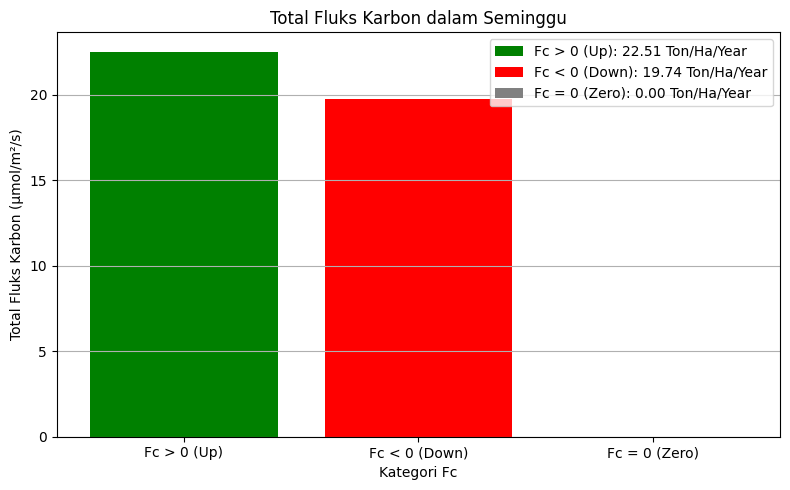

In [ ]:
# Ambil kolom Fc
Fc = final_flux['ton_flux_year']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].mean()
Fc_neg_sum = -Fc[Fc < 0].mean()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].mean()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} Ton/Ha/Year")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Menyimpan Data

In [ ]:
# Simpan data ke csv
final_flux.to_csv('/content/drive/MyDrive/Data Fluks/Hasil/Data_new_Parameter.csv')